In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 机器学习相关库
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 设置中文字体，解决画图时中文显示为方块的问题
plt.rcParams['font.sans-serif'] = ['SimHei', 'Arial Unicode MS', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

# 1. 加载数据集
iris = load_iris()

# 2. 翻译特征名和类别名 (修复了原代码的中文引号和错别字)
feature_names_cn = ['花萼长度(cm)', '花萼宽度(cm)', '花瓣长度(cm)', '花瓣宽度(cm)']
target_names_cn = ['山鸢尾', '变色鸢尾', '维吉尼亚鸢尾']

# 3. 转换成表格 (DataFrame) 形式展示
df = pd.DataFrame(iris.data, columns=feature_names_cn)
df['最终分类结果'] = [target_names_cn[i] for i in iris.target]

# 4. 数据集前5行预览
print("========== 数据集前5行预览 ==========")
display(df.head()) # 在Jupyter中使用 display() 比 print() 更美观

print(f"\n数据集形状: {df.shape}")
print(f"各类别样本数量:\n{df['最终分类结果'].value_counts()}")

========== 数据集前5行预览 ==========


,花萼长度(cm),花萼宽度(cm),花瓣长度(cm),花瓣宽度(cm),最终分类结果
0,5.1,3.5,1.4,0.2,山鸢尾
1,4.9,3.0,1.4,0.2,山鸢尾
2,4.7,3.2,1.3,0.2,山鸢尾
3,4.6,3.1,1.5,0.2,山鸢尾
4,5.0,3.6,1.4,0.2,山鸢尾



数据集形状: (150, 5)
各类别样本数量:
最终分类结果
山鸢尾       50
变色鸢尾      50
维吉尼亚鸢尾    50
Name: count, dtype: int64


In [2]:
# 提取特征 (X) 和 标签 (y)
X = df[feature_names_cn]
y = df['最终分类结果']

# 划分训练集和测试集 (80%训练，20%测试)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"训练集大小: {X_train.shape[0]} 条")
print(f"测试集大小: {X_test.shape[0]} 条")

训练集大小: 120 条
测试集大小: 30 条


In [3]:
# 初始化决策树模型
# max_depth=3 是为了限制树的深度，方便后续可视化学习，同时也防止过拟合
clf = DecisionTreeClassifier(criterion='gini', max_depth=3, random_state=42)

# 训练模型
clf.fit(X_train, y_train)

# 在测试集上进行预测
y_pred = clf.predict(X_test)

# 评估模型
acc = accuracy_score(y_test, y_pred)
print(f"模型在测试集上的准确率: {acc:.2f} (即 {acc*100:.1f}%)")
print("\n分类报告:")
print(classification_report(y_test, y_pred))

模型在测试集上的准确率: 1.00 (即 100.0%)

分类报告:
              precision    recall  f1-score   support

        变色鸢尾       1.00      1.00      1.00         9
         山鸢尾       1.00      1.00      1.00        10
      维吉尼亚鸢尾       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30


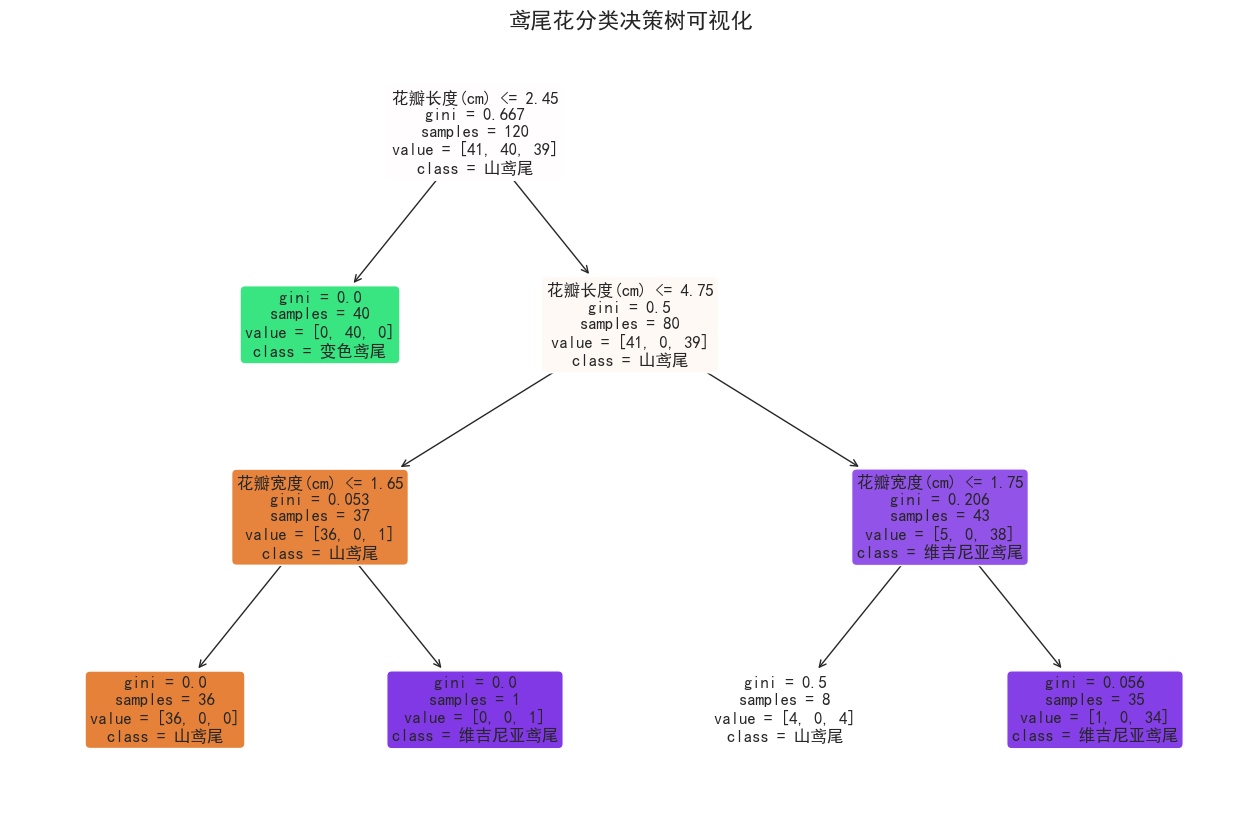

In [4]:
# 绘制决策树图
plt.figure(figsize=(16, 10))
plot_tree(clf, 
          feature_names=feature_names_cn,  # 使用中文特征名
          class_names=target_names_cn,     # 使用中文类别名
          filled=True,                     # 给节点填充颜色，颜色越深纯度越高
          rounded=True,                    # 节点框圆角
          fontsize=12)

plt.title("鸢尾花分类决策树可视化", fontsize=16)
plt.show()

C:\Users\27813\AppData\Local\Temp\ipykernel_28964\515879162.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='重要性', y='特征', data=feature_importance_df, palette='viridis')


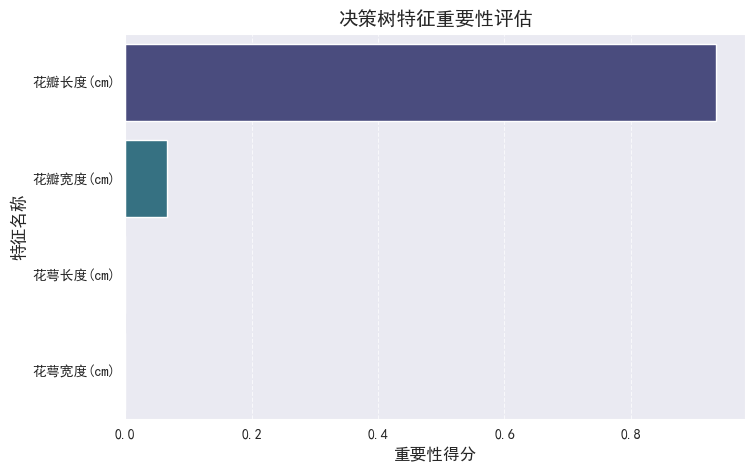

         特征       重要性
2  花瓣长度(cm)  0.934626
3  花瓣宽度(cm)  0.065374
0  花萼长度(cm)  0.000000
1  花萼宽度(cm)  0.000000


In [5]:
# 获取特征重要性
importances = clf.feature_importances_

# 整理成 DataFrame 方便画图
feature_importance_df = pd.DataFrame({
    '特征': feature_names_cn,
    '重要性': importances
}).sort_values(by='重要性', ascending=False)

# 可视化特征重要性
plt.figure(figsize=(8, 5))
sns.barplot(x='重要性', y='特征', data=feature_importance_df, palette='viridis')
plt.title('决策树特征重要性评估', fontsize=14)
plt.xlabel('重要性得分', fontsize=12)
plt.ylabel('特征名称', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()

print(feature_importance_df)

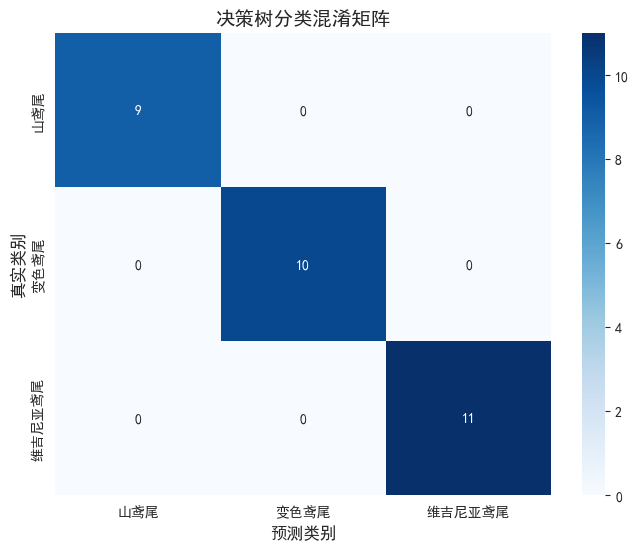

In [6]:
# 计算混淆矩阵
cm = confusion_matrix(y_test, y_pred)

# 绘制混淆矩阵热力图
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=target_names_cn, 
            yticklabels=target_names_cn)
plt.title('决策树分类混淆矩阵', fontsize=14)
plt.xlabel('预测类别', fontsize=12)
plt.ylabel('真实类别', fontsize=12)
plt.show()